# 02 — Spatial and Temporal Analysis


## Research question

How do graph choices and evaluation partitions change what can be learned from
the synthetic observations? This notebook inspects coordinates, distances,
connectivity, coverage, and leakage risk progressively.

The working assumption is purely computational: nearby normalized coordinates
may provide a useful neighbourhood for comparison. Geographic proximity does
not prove physical communication. Evidence is limited to the synthetic domain,
and the main limitation is that graph edges have no independently observed
physical meaning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.spatial import distance_matrix

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
observations = pd.read_csv("data/generated/observations.csv")
sites = pd.read_csv("data/generated/sites.csv")
observations.shape, sites.shape

((864, 12), (24, 3))

## Reinspect inputs before relationships

The data are loaded from Notebook 01 rather than regenerated silently. We first
check schema, uniqueness, coordinate extents, and temporal coverage. These
diagnostics guard against building a graph over duplicated sites or constructing
splits from an incomplete period range.

In [3]:
observations.head(8)

,site_id,x_norm,y_norm,period,synthetic_month,spatial_component,temporal_component,seasonal_component,perturbation_component,site_offset,pressure_su,is_missing
0,S00,0.369331,0.516951,0,2000-01,0.383147,0.000,0.000000,0.0,0.599744,10.952635,False
1,S00,0.369331,0.516951,1,2000-02,0.383147,0.035,0.175000,0.0,0.599744,11.172264,False
2,S00,0.369331,0.516951,2,2000-03,0.383147,0.070,0.303109,0.0,0.599744,11.504044,False
3,S00,0.369331,0.516951,3,2000-04,0.383147,0.105,0.350000,0.0,0.599744,11.466934,False
4,S00,0.369331,0.516951,4,2000-05,0.383147,0.140,0.303109,0.0,0.599744,11.205454,False
5,S00,0.369331,0.516951,5,2000-06,0.383147,0.175,0.175000,0.0,0.599744,11.539088,False
6,S00,0.369331,0.516951,6,2000-07,0.383147,0.210,0.000000,0.0,0.599744,11.331876,False
7,S00,0.369331,0.516951,7,2000-08,0.383147,0.245,-0.175000,0.0,0.599744,10.988715,False


In [4]:
schema = pd.DataFrame({
    "dtype": observations.dtypes.astype(str),
    "missing": observations.isna().sum(),
    "unique": observations.nunique(dropna=True),
})
schema

,dtype,missing,unique
site_id,object,0,24
x_norm,float64,0,24
y_norm,float64,0,24
period,int64,0,36
synthetic_month,object,0,36
spatial_component,float64,0,24
temporal_component,float64,0,36
seasonal_component,float64,0,7
perturbation_component,float64,0,25
site_offset,float64,0,24


In [5]:
input_checks = pd.Series({
    "duplicate site-period rows": observations.duplicated(["site_id", "period"]).sum(),
    "unique sites": observations["site_id"].nunique(),
    "period minimum": observations["period"].min(),
    "period maximum": observations["period"].max(),
    "observed fraction": observations["pressure_su"].notna().mean(),
})
input_checks.to_frame("value")

,value
duplicate site-period rows,0.000000
unique sites,24.000000
period minimum,0.000000
period maximum,35.000000
observed fraction,0.927083


In [6]:
assert input_checks["duplicate site-period rows"] == 0
assert input_checks["unique sites"] == len(sites)
assert observations["period"].nunique() == 36
sites[["x_norm", "y_norm"]].agg(["min", "max"])

,x_norm,y_norm
min,0.063082,0.050211
max,0.937448,0.909901


The checks confirm the intended dimensions and complete period index, although
individual pressure observations still contain designed gaps. That distinction
matters: temporal coverage of the table is not the same as observed target
coverage.

## Inspect distances before choosing edges

Euclidean distance is calculated in normalized coordinates. The diagonal is
excluded from the distribution because self-distance is not a candidate edge.
We examine quantiles before testing thresholds, rather than selecting a graph
from an unexplained constant.

In [7]:
coordinates = sites.set_index("site_id")[["x_norm", "y_norm"]]
distances = pd.DataFrame(
    distance_matrix(coordinates, coordinates),
    index=coordinates.index,
    columns=coordinates.index,
)
pairwise = distances.where(np.triu(np.ones(distances.shape), k=1).astype(bool)).stack()
pairwise.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

count    276.000000
mean       0.457043
std        0.224197
min        0.002139
10%        0.166432
25%        0.281111
50%        0.458694
75%        0.617117
90%        0.770850
max        0.925982
dtype: float64

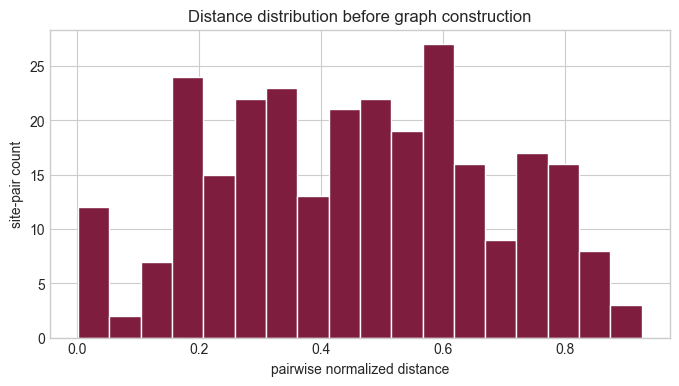

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pairwise, bins=18, color="#7f1d3f", edgecolor="white")
ax.set(xlabel="pairwise normalized distance", ylabel="site-pair count", title="Distance distribution before graph construction")
plt.show()

In [9]:
nearest = distances.replace(0, np.nan).min(axis=1)
nearest.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).to_frame("nearest_distance")

,nearest_distance
count,24.000000
mean,0.084871
std,0.063788
min,0.002139
25%,0.032605
50%,0.061324
75%,0.150862
90%,0.162990
max,0.213290


The broad pairwise distribution and narrower nearest-neighbour range suggest
that connectivity is sensitive to a threshold near the upper nearest-distance
quantiles. This is exploratory evidence for testing several thresholds, not a
physical communication radius.

## Compare neighbourhood assumptions

For each candidate threshold we count edges, connected components, isolated
nodes, and degree spread. We select one graph only after seeing these
diagnostics. Changing the threshold is the sole changed assumption.

In [10]:
graph_rows = []
for threshold in [0.18, 0.24, 0.30, 0.36]:
    graph = nx.Graph()
    graph.add_nodes_from(coordinates.index)
    graph.add_edges_from((a, b) for (a, b), value in pairwise.items() if value <= threshold)
    degrees = np.array([degree for _, degree in graph.degree()])
    graph_rows.append({
        "threshold": threshold, "edges": graph.number_of_edges(),
        "components": nx.number_connected_components(graph),
        "isolated": len(list(nx.isolates(graph))), "median_degree": np.median(degrees),
    })
pd.DataFrame(graph_rows)

,threshold,edges,components,isolated,median_degree
0,0.18,33,5,1,3.0
1,0.24,57,2,0,5.0
2,0.30,76,2,0,7.0
3,0.36,104,1,0,8.5


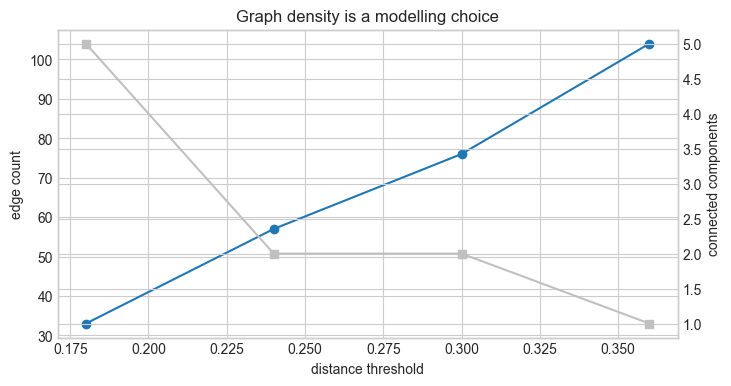

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sensitivity = pd.DataFrame(graph_rows)
ax.plot(sensitivity["threshold"], sensitivity["edges"], marker="o", label="edges")
ax.set(xlabel="distance threshold", ylabel="edge count", title="Graph density is a modelling choice")
ax2 = ax.twinx()
ax2.plot(sensitivity["threshold"], sensitivity["components"], marker="s", color="silver", label="components")
ax2.set_ylabel("connected components")
plt.show()

In [12]:
SELECTED_THRESHOLD = 0.36
graph = nx.Graph()
graph.add_nodes_from(coordinates.index)
selected_edges = [(a, b, {"distance": value}) for (a, b), value in pairwise.items() if value <= SELECTED_THRESHOLD]
graph.add_edges_from(selected_edges)
degree_table = pd.Series(dict(graph.degree()), name="degree").to_frame()
degree_table.describe().T

,count,mean,std,min,25%,50%,75%,max
degree,24.0,8.666667,2.853932,3.0,7.0,8.5,11.0,13.0


In [13]:
degree_table.sort_values("degree").head(8)

,degree
S13,3
S21,3
S19,5
S01,7
S12,7
S22,7
S06,7
S02,7


In [14]:
assert graph.number_of_nodes() == len(sites)
assert not list(nx.isolates(graph))
assert nx.is_connected(graph)

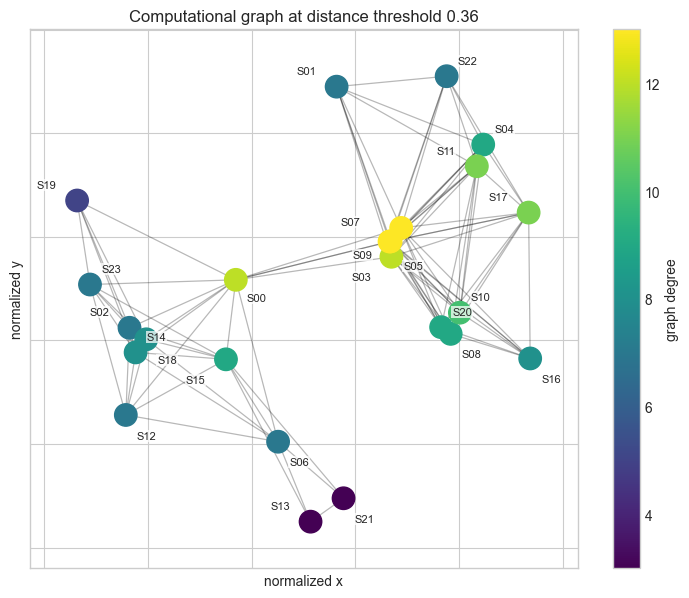

In [15]:
position = {site: tuple(coordinates.loc[site]) for site in coordinates.index}
node_degrees = [graph.degree(site) for site in coordinates.index]
fig, ax = plt.subplots(figsize=(9, 7))
nx.draw_networkx_edges(graph, position, ax=ax, alpha=0.28, width=0.9)
nodes = nx.draw_networkx_nodes(graph, position, ax=ax, nodelist=coordinates.index, node_color=node_degrees, cmap="viridis", node_size=260)
label_offsets = {site: (8, 9) for site in coordinates.index}
label_offsets.update({
    "S00": (8, -15), "S01": (-29, 9), "S02": (-29, 9), "S03": (-29, -17),
    "S05": (9, -20), "S06": (8, -17), "S07": (-35, 12), "S08": (8, -17), "S09": (-35, -22),
    "S11": (-29, 9), "S12": (8, -17), "S13": (-29, 9), "S15": (-29, -17),
    "S16": (8, -17), "S17": (-29, 9), "S18": (8, -17), "S19": (-29, 9), "S21": (8, -17),
})
for site, (x_value, y_value) in position.items():
    offset = label_offsets[site]
    ax.annotate(site, (x_value, y_value), xytext=offset, textcoords="offset points", fontsize=8, bbox={"facecolor": "white", "alpha": 0.72, "edgecolor": "none", "pad": 0.7})
fig.colorbar(nodes, ax=ax, label="graph degree")
ax.set(title=f"Computational graph at distance threshold {SELECTED_THRESHOLD}", xlabel="normalized x", ylabel="normalized y")
ax.set_aspect("equal")
Path("docs/images").mkdir(parents=True, exist_ok=True)
fig.savefig("docs/images/computational_graph.png", dpi=150, bbox_inches="tight")
plt.show()

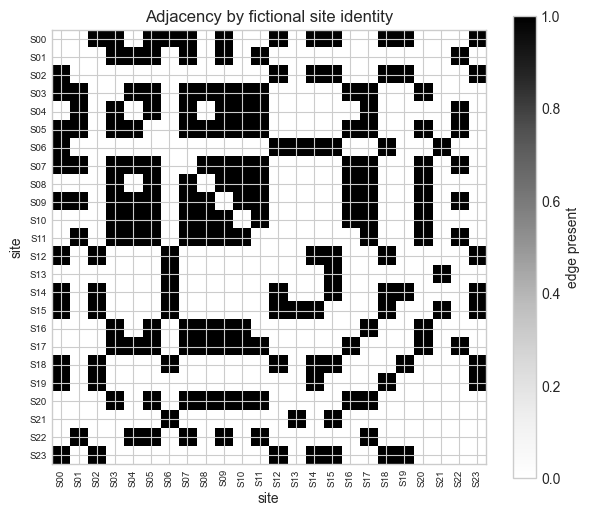

In [16]:
adjacency = nx.to_numpy_array(graph, nodelist=coordinates.index)
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(adjacency, cmap="Greys", interpolation="nearest")
indices = np.arange(len(coordinates.index))
ax.set_xticks(indices, labels=coordinates.index, rotation=90, fontsize=7)
ax.set_yticks(indices, labels=coordinates.index, fontsize=7)
ax.set(title="Adjacency by fictional site identity", xlabel="site", ylabel="site")
fig.colorbar(image, ax=ax, label="edge present")
plt.show()

The selected graph is connected and contains no isolated nodes, which is useful
for later computational experiments. The sensitivity table shows that this
property is not inevitable: smaller thresholds fragment the graph. The graph
therefore records a transparent analytical choice, not evidence of subsurface
communication.

## Inspect time coverage before evaluation partitions

We next count observations by period and site. Chronological evaluation should
train only on earlier periods. A random row split is shown as a leakage-risk
example because it places later and earlier observations in both partitions.

In [17]:
coverage_by_period = observations.groupby("period")["pressure_su"].agg(
    observed="count", missing=lambda values: values.isna().sum()
)
coverage_by_period.T

period,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
observed,20,23,22,23,24,23,23,24,23,23,...,23,24,19,22,23,23,22,23,23,23
missing,4,1,2,1,0,1,1,0,1,1,...,1,0,5,2,1,1,2,1,1,1


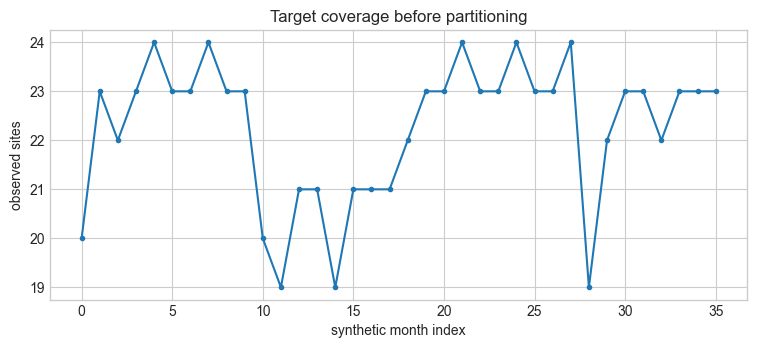

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(coverage_by_period.index, coverage_by_period["observed"], marker="o", markersize=3)
ax.set(xlabel="synthetic month index", ylabel="observed sites", title="Target coverage before partitioning")
plt.show()

In [19]:
CUTOFF = 27
observations["chronological_role"] = np.where(
    observations["period"] <= CUTOFF, "train", "test"
)
chronological_summary = observations.groupby("chronological_role")["period"].agg(["min", "max", "nunique"])
chronological_summary

,min,max,nunique
chronological_role,,,
test,28,35,8
train,0,27,28


In [20]:
train_periods = observations.loc[observations["chronological_role"] == "train", "period"]
test_periods = observations.loc[observations["chronological_role"] == "test", "period"]
assert set(train_periods) == set(range(28))
assert set(test_periods) == set(range(28, 36))
assert train_periods.max() < test_periods.min()
assert set(train_periods).isdisjoint(set(test_periods))

The chronological partition enforces the intended direction of time. Training
uses periods 0–27 and testing uses periods 28–35: exactly eight later test
periods, with no period shared between roles. This does not prevent every
possible form of leakage—for example, preprocessing fitted on the full table
would still be unsafe—so feature construction must respect the partition too.

In [21]:
split_rng = np.random.default_rng(73)
random_roles = split_rng.choice(["train", "test"], size=len(observations), p=[0.8, 0.2])
random_example = observations.assign(random_role=random_roles).groupby("random_role")["period"].agg(["min", "max", "nunique"])
random_example

,min,max,nunique
random_role,,,
test,0,35,36
train,0,35,36


In [22]:
random_train_periods = set(observations.loc[random_roles == "train", "period"])
random_test_periods = set(observations.loc[random_roles == "test", "period"])
pd.Series({
    "shared periods": len(random_train_periods & random_test_periods),
    "latest training period": max(random_train_periods),
    "earliest test period": min(random_test_periods),
})

shared periods            36
latest training period    35
earliest test period       0
dtype: int64

The random-row example mixes all periods across training and test. That can be
acceptable for a narrowly defined interpolation question, but it is invalid
evidence for future-period prediction. The example is retained as a diagnostic
counterexample rather than an accepted method.

## Construct a separate spatial holdout

To examine spatial generalization, the five easternmost fictional sites are
withheld. The rule is deliberately simple and visible. It creates a harder
boundary test but is not representative of every deployment geometry.

In [23]:
held_out_sites = set(sites.nlargest(5, "x_norm")["site_id"])
observations["spatial_role"] = np.where(
    observations["site_id"].isin(held_out_sites), "test", "train"
)
spatial_membership = sites.assign(
    role=np.where(sites["site_id"].isin(held_out_sites), "test", "train")
)
spatial_membership.groupby("role")[["x_norm", "y_norm"]].agg(["count", "min", "max"])

x_norm                     y_norm                    
       count       min       max  count       min       max
role                                                       
test       5  0.801772  0.937448      5  0.365197  0.777981
train     19  0.063082  0.784006     19  0.050211  0.909901

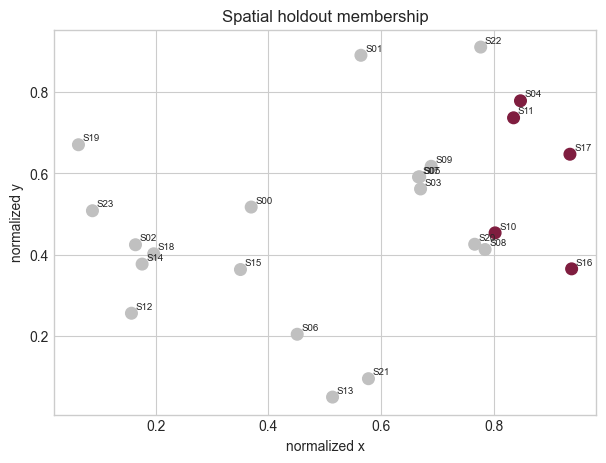

In [24]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = spatial_membership["role"].map({"train": "silver", "test": "#7f1d3f"})
ax.scatter(spatial_membership["x_norm"], spatial_membership["y_norm"], c=colors, s=70)
for row in spatial_membership.itertuples():
    ax.annotate(row.site_id, (row.x_norm, row.y_norm), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="normalized x", ylabel="normalized y", title="Spatial holdout membership")
plt.show()

In [25]:
train_sites = set(observations.loc[observations["spatial_role"] == "train", "site_id"])
test_sites = set(observations.loc[observations["spatial_role"] == "test", "site_id"])
assert train_sites.isdisjoint(test_sites)
assert train_sites | test_sites == set(sites["site_id"])

The spatial split is disjoint by site and concentrates the evaluation region
near one domain boundary. It tests extrapolation-like behavior more than random
site withholding. Its evidence should therefore be interpreted alongside the
partition geometry, not summarized by one error number.

## Check feature provenance and save partition evidence

Coordinates, period index, and graph membership are available without target
values. Component columns from the generator would reveal the answer and are
therefore excluded from baseline inputs. This explicit inventory is a target
leakage check.

In [26]:
feature_audit = pd.DataFrame([
    {"feature": "x_norm / y_norm", "available_without_target": True, "baseline_input": True},
    {"feature": "period", "available_without_target": True, "baseline_input": True},
    {"feature": "graph edges", "available_without_target": True, "baseline_input": False},
    {"feature": "generator components", "available_without_target": False, "baseline_input": False},
    {"feature": "pressure_su", "available_without_target": False, "baseline_input": False},
])
feature_audit

,feature,available_without_target,baseline_input
0,x_norm / y_norm,True,True
1,period,True,True
2,graph edges,True,False
3,generator components,False,False
4,pressure_su,False,False


In [27]:
partitions = observations[[
    "site_id", "period", "pressure_su", "chronological_role", "spatial_role"
]].copy()
edge_table = pd.DataFrame(
    [(a, b, data["distance"]) for a, b, data in graph.edges(data=True)],
    columns=["site_a", "site_b", "distance"],
).sort_values(["site_a", "site_b"])

In [28]:
output_dir = Path("data/generated")
partitions.to_csv(output_dir / "partitions.csv", index=False, float_format="%.8f", lineterminator="\n")
edge_table.to_csv(output_dir / "graph_edges.csv", index=False, float_format="%.8f", lineterminator="\n")
partitions.shape, edge_table.shape

((864, 5), (104, 3))

## Conclusion and limitations

The evidence supports a connected computational graph at the selected
threshold and two disjoint evaluation protocols: later-period prediction and
eastern-boundary spatial withholding. The threshold sensitivity and random
split counterexample show why these choices must remain visible.

Nothing in this analysis establishes reservoir communication, causal influence,
or transfer to real locations. The next notebook should introduce simple
baselines individually, inspect their predictions and residuals, and compare
the two holdouts without collapsing their different scientific questions.